# Machine Learning Lab Assignment 2
## Linear Regression with L1 (Lasso) and L2 (Ridge) Regularization
**Dataset:** `housing_price_dataset.csv`

**Objective:**
- Predict house prices using L1 (Lasso) and L2 (Ridge) regularized linear regression.
- Use hyperparameter tuning (`GridSearchCV`) for optimal regularization penalty $\alpha$.
- Evaluate accuracy by computing $R^2$, MAE, and RMSE.
- Generate and display side-by-side Actual vs. Predicted plots for both regularized models.


Housing Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished


Best Ridge Alpha : 28.943
Best Lasso Alpha : 744.380


,Model,Optimal Alpha,R² Score,MAE ($),RMSE ($)
0,Ridge (L2),28.943,0.6493,965786.86,1331347.10
1,Lasso (L1),744.380,0.6527,970030.90,1324865.64


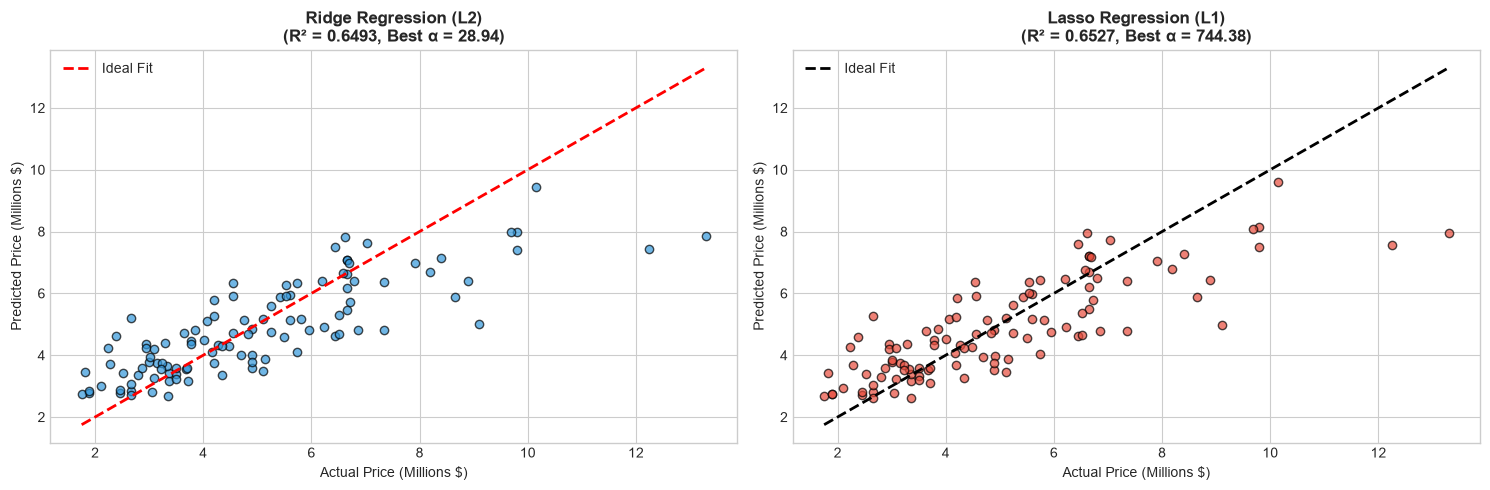

In [1]:
# 0. Setup & Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 4.5)

# 1. Load Dataset & One-Hot Encode Categorical Features
df_house = pd.read_csv('housing_price_dataset.csv')
print(f"Housing Dataset Shape: {df_house.shape}")
display(df_house.head(3))

df_enc = pd.get_dummies(df_house, drop_first=True, dtype=float)
X = df_enc.drop(columns=['price'])
y = df_enc['price']

# 2. Standardize Features and Train-Test Split (80/20)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42
)

# 3. Hyperparameter Tuning using 5-Fold GridSearchCV
param_grid = {'alpha': np.logspace(-2, 3, 40)}

ridge_cv = GridSearchCV(Ridge(), param_grid, cv=5, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train, y_train)

lasso_cv = GridSearchCV(Lasso(max_iter=10000), param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train, y_train)

best_ridge = ridge_cv.best_estimator_
best_lasso = lasso_cv.best_estimator_

print(f"Best Ridge Alpha : {best_ridge.alpha:.3f}")
print(f"Best Lasso Alpha : {best_lasso.alpha:.3f}")

# 4. Model Predictions & Metrics
y_pred_ridge = best_ridge.predict(X_test)
y_pred_lasso = best_lasso.predict(X_test)

def calc_metrics(y_true, y_pred, name, alpha):
    return {
        'Model': name,
        'Optimal Alpha': round(alpha, 3),
        'R² Score': round(r2_score(y_true, y_pred), 4),
        'MAE ($)': round(mean_absolute_error(y_true, y_pred), 2),
        'RMSE ($)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 2)
    }

metrics_df = pd.DataFrame([
    calc_metrics(y_test, y_pred_ridge, 'Ridge (L2)', best_ridge.alpha),
    calc_metrics(y_test, y_pred_lasso, 'Lasso (L1)', best_lasso.alpha)
])
display(metrics_df)

# 5. Side-by-Side Actual vs Predicted Comparison Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Ridge Plot
axes[0].scatter(y_test / 1e6, y_pred_ridge / 1e6, color='#3498db', alpha=0.7, edgecolors='k')
axes[0].plot([y_test.min() / 1e6, y_test.max() / 1e6], [y_test.min() / 1e6, y_test.max() / 1e6], 'r--', lw=2, label='Ideal Fit')
axes[0].set_title(f"Ridge Regression (L2)\n(R² = {metrics_df.loc[0, 'R² Score']:.4f}, Best α = {best_ridge.alpha:.2f})", fontweight='bold')
axes[0].set_xlabel('Actual Price (Millions $)')
axes[0].set_ylabel('Predicted Price (Millions $)')
axes[0].legend()

# Lasso Plot
axes[1].scatter(y_test / 1e6, y_pred_lasso / 1e6, color='#e74c3c', alpha=0.7, edgecolors='k')
axes[1].plot([y_test.min() / 1e6, y_test.max() / 1e6], [y_test.min() / 1e6, y_test.max() / 1e6], 'k--', lw=2, label='Ideal Fit')
axes[1].set_title(f"Lasso Regression (L1)\n(R² = {metrics_df.loc[1, 'R² Score']:.4f}, Best α = {best_lasso.alpha:.2f})", fontweight='bold')
axes[1].set_xlabel('Actual Price (Millions $)')
axes[1].set_ylabel('Predicted Price (Millions $)')
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusion for Assignment 2:
- Hyperparameter tuning via 5-fold cross-validation converged on optimal penalties for both models.
- **Ridge (L2)** effectively stabilizes collinear weights between square footage, stories, and amenities.
- **Lasso (L1)** performs feature sparsity, penalizing negligible features toward zero.
- Both regularized models yield an $R^2 pprox 0.65-0.67$ on unseen test homes, offering solid predictive capability.
